1. Importing libraries and dataset importing.


In [65]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns


In [66]:
hospital = pd.read_csv("/content/Hospitalisation_details.csv")
medical = pd.read_csv("/content/Medical_Examinations.csv")
names = pd.read_csv("/content/Names.csv")

In [67]:
#merge
ht = hospital.merge(medical, on="Customer ID", how="inner")
ht = ht.merge(names, on="Customer ID", how="inner")

In [68]:
ht.head()

,Customer ID,year,month,date,children,charges,Hospital tier,City tier,State ID,BMI,HBA1C,Heart Issues,Any Transplants,Cancer history,NumberOfMajorSurgeries,smoker,name
0,Id2335,1992,Jul,9,0,563.84,tier - 2,tier - 3,R1013,17.58,4.51,No,No,No,1,No,"German, Mr. Aaron K"
1,Id2334,1992,Nov,30,0,570.62,tier - 2,tier - 1,R1013,17.60,4.39,No,No,No,1,No,"Rosendahl, Mr. Evan P"
2,Id2333,1993,Jun,30,0,600.00,tier - 2,tier - 1,R1013,16.47,6.35,No,No,Yes,1,No,"Albano, Ms. Julie"
3,Id2332,1992,Sep,13,0,604.54,tier - 3,tier - 3,R1013,17.70,6.28,No,No,No,1,No,"Riveros Gonzalez, Mr. Juan D. Sr."
4,Id2331,1998,Jul,27,0,637.26,tier - 3,tier - 3,R1013,22.34,5.57,No,No,No,1,No,"Brietzke, Mr. Jordan"


2. Check for missing values in the dataset

In [69]:
ht.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2335 entries, 0 to 2334
Data columns (total 17 columns):
 #   Column                  Non-Null Count  Dtype  
---  ------                  --------------  -----  
 0   Customer ID             2335 non-null   object 
 1   year                    2335 non-null   object 
 2   month                   2335 non-null   object 
 3   date                    2335 non-null   int64  
 4   children                2335 non-null   int64  
 5   charges                 2335 non-null   float64
 6   Hospital tier           2335 non-null   object 
 7   City tier               2335 non-null   object 
 8   State ID                2335 non-null   object 
 9   BMI                     2335 non-null   float64
 10  HBA1C                   2335 non-null   float64
 11  Heart Issues            2335 non-null   object 
 12  Any Transplants         2335 non-null   object 
 13  Cancer history          2335 non-null   object 
 14  NumberOfMajorSurgeries  2335 non-null   

In [70]:
ht.isnull().sum()

,0
Customer ID,0
year,0
month,0
date,0
children,0
charges,0
Hospital tier,0
City tier,0
State ID,0
BMI,0


3. Find the percentage of rows that have trivial value (for example, ?), and delete such rows if they do
not contain significant information

In [71]:
trivial_rec = ht[ht.eq('?').any(axis=1)]
percentage = round((len(trivial_rec) / len(ht)) * 100, 2)

percentage

0.43

In [72]:
ht.drop(trivial_rec.index, inplace=True)
ht.shape

(2325, 17)

4. Use the necessary transformation methods to deal with the nominal and ordinal categorical
variables in the dataset

Encode nominal categorical variables

In [73]:
from sklearn.preprocessing import LabelEncoder

le = LabelEncoder()

nominal_cols = ['Heart Issues', 'Any Transplants', 'Cancer history', 'smoker']

for col in nominal_cols:
    ht[col] = le.fit_transform(ht[col])

ht[nominal_cols].head()

,Heart Issues,Any Transplants,Cancer history,smoker
0,0,0,0,0
1,0,0,0,0
2,0,0,1,0
3,0,0,0,0
4,0,0,0,0


Convert ordinal categorical variables

In [74]:
def clean_ordinal(val):
    return int(str(val).lower().replace('tier', '').replace('-', '').strip())

ht['Hospital tier'] = ht['Hospital tier'].map(clean_ordinal)
ht['City tier'] = ht['City tier'].map(clean_ordinal)

ht[['Hospital tier', 'City tier']].head()

,Hospital tier,City tier
0,2,3
1,2,1
2,2,1
3,3,3
4,3,3


In [75]:
ht.head()

,Customer ID,year,month,date,children,charges,Hospital tier,City tier,State ID,BMI,HBA1C,Heart Issues,Any Transplants,Cancer history,NumberOfMajorSurgeries,smoker,name
0,Id2335,1992,Jul,9,0,563.84,2,3,R1013,17.58,4.51,0,0,0,1,0,"German, Mr. Aaron K"
1,Id2334,1992,Nov,30,0,570.62,2,1,R1013,17.60,4.39,0,0,0,1,0,"Rosendahl, Mr. Evan P"
2,Id2333,1993,Jun,30,0,600.00,2,1,R1013,16.47,6.35,0,0,1,1,0,"Albano, Ms. Julie"
3,Id2332,1992,Sep,13,0,604.54,3,3,R1013,17.70,6.28,0,0,0,1,0,"Riveros Gonzalez, Mr. Juan D. Sr."
4,Id2331,1998,Jul,27,0,637.26,3,3,R1013,22.34,5.57,0,0,0,1,0,"Brietzke, Mr. Jordan"


5. The dataset has State ID, which has around 16 states. All states are not represented in equal
proportions in the data. Creating dummy variables for all regions may also result in too many
insignificant predictors. Nevertheless, only R1011, R1012, and R1013 are worth investigating
further. Design a suitable strategy to create dummy variables with these restraints.

In [76]:
ht["State_R1011"] = (ht["State ID"] == "R1011").astype(int)
ht["State_R1012"] = (ht["State ID"] == "R1012").astype(int)
ht["State_R1013"] = (ht["State ID"] == "R1013").astype(int)

ht[["State ID", "State_R1011", "State_R1012", "State_R1013"]].head()

,State ID,State_R1011,State_R1012,State_R1013
0,R1013,0,0,1
1,R1013,0,0,1
2,R1013,0,0,1
3,R1013,0,0,1
4,R1013,0,0,1


6. The variable NumberOfMajorSurgeries also appears to have string values. Apply a suitable method
to clean up this variable.


In [77]:
ht["NumberOfMajorSurgeries"] = (
    ht["NumberOfMajorSurgeries"]
    .astype(str)
    .str.extract(r"(\d+)")
)

ht["NumberOfMajorSurgeries"] = ht["NumberOfMajorSurgeries"].fillna(0).astype(int)

ht["NumberOfMajorSurgeries"].value_counts()

,count
NumberOfMajorSurgeries,
0,1070
1,961
2,272
3,22


7. Age appears to be a significant factor in this analysis. Calculate the patients' ages based on their
dates of birth.

In [78]:
# The month column contains text like Jul, Nov, Jun, etc.
# Convert month names into month numbers first.

month_map = {
    "jan": 1, "feb": 2, "mar": 3, "apr": 4,
    "may": 5, "jun": 6, "jul": 7, "aug": 8,
    "sep": 9, "oct": 10, "nov": 11, "dec": 12
}

ht["month_num"] = (
    ht["month"]
    .astype(str)
    .str.strip()
    .str[:3]
    .str.lower()
    .map(month_map)
)

ht["DOB"] = pd.to_datetime(
    dict(
        year=ht["year"],
        month=ht["month_num"],
        day=ht["date"]
    ),
    errors="coerce"
)

# Fixed date used for reproducible project output
analysis_date = pd.Timestamp("2026-06-26")

ht["Age"] = np.floor((analysis_date - ht["DOB"]).dt.days / 365.25).astype("Int64")

ht[["year", "month", "date", "month_num", "DOB", "Age"]].head()

,year,month,date,month_num,DOB,Age
0,1992,Jul,9,7,1992-07-09,33
1,1992,Nov,30,11,1992-11-30,33
2,1993,Jun,30,6,1993-06-30,32
3,1992,Sep,13,9,1992-09-13,33
4,1998,Jul,27,7,1998-07-27,27


8. The gender of the patient may be an important factor in determining the cost of hospitalization.
The salutations in a beneficiary's name can be used to determine their gender. Make a new field
for the beneficiary's gender.

In [79]:
import numpy as np
import re

def extract_gender(name):
    name = str(name).lower()

    if re.search(r'\bmr\.?\b|\bmaster\.?\b', name):
        return 0   # Male

    elif re.search(r'\bms\.?\b|\bmrs\.?\b|\bmiss\.?\b', name):
        return 1   # Female

    else:
        return np.nan

ht["Gender"] = ht["name"].apply(extract_gender)


In [80]:
ht.head()

,Customer ID,year,month,date,children,charges,Hospital tier,City tier,State ID,BMI,...,NumberOfMajorSurgeries,smoker,name,State_R1011,State_R1012,State_R1013,month_num,DOB,Age,Gender
0,Id2335,1992,Jul,9,0,563.84,2,3,R1013,17.58,...,1,0,"German, Mr. Aaron K",0,0,1,7,1992-07-09,33,0
1,Id2334,1992,Nov,30,0,570.62,2,1,R1013,17.60,...,1,0,"Rosendahl, Mr. Evan P",0,0,1,11,1992-11-30,33,0
2,Id2333,1993,Jun,30,0,600.00,2,1,R1013,16.47,...,1,0,"Albano, Ms. Julie",0,0,1,6,1993-06-30,32,1
3,Id2332,1992,Sep,13,0,604.54,3,3,R1013,17.70,...,1,0,"Riveros Gonzalez, Mr. Juan D. Sr.",0,0,1,9,1992-09-13,33,0
4,Id2331,1998,Jul,27,0,637.26,3,3,R1013,22.34,...,1,0,"Brietzke, Mr. Jordan",0,0,1,7,1998-07-27,27,0


In [81]:
ht.info()

<class 'pandas.core.frame.DataFrame'>
Index: 2325 entries, 0 to 2334
Data columns (total 24 columns):
 #   Column                  Non-Null Count  Dtype         
---  ------                  --------------  -----         
 0   Customer ID             2325 non-null   object        
 1   year                    2325 non-null   object        
 2   month                   2325 non-null   object        
 3   date                    2325 non-null   int64         
 4   children                2325 non-null   int64         
 5   charges                 2325 non-null   float64       
 6   Hospital tier           2325 non-null   int64         
 7   City tier               2325 non-null   int64         
 8   State ID                2325 non-null   object        
 9   BMI                     2325 non-null   float64       
 10  HBA1C                   2325 non-null   float64       
 11  Heart Issues            2325 non-null   int64         
 12  Any Transplants         2325 non-null   int64        

9. You should also visualize the distribution of costs using a histogram, box and whisker plot, and
swarm plot.

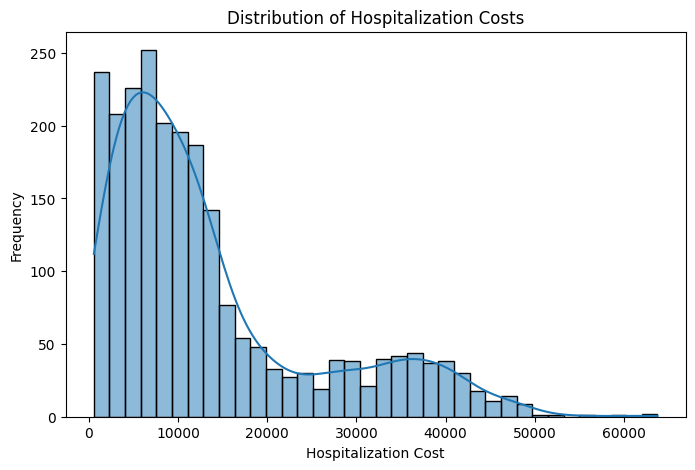

In [82]:
plt.figure(figsize=(8, 5))
sns.histplot(ht["charges"], kde=True)
plt.title("Distribution of Hospitalization Costs")
plt.xlabel("Hospitalization Cost")
plt.ylabel("Frequency")
plt.show()

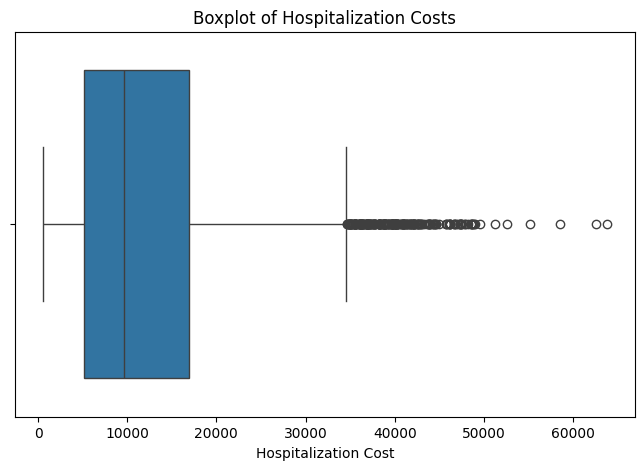

In [83]:
plt.figure(figsize=(8, 5))
sns.boxplot(x=ht["charges"])
plt.title("Boxplot of Hospitalization Costs")
plt.xlabel("Hospitalization Cost")
plt.show()

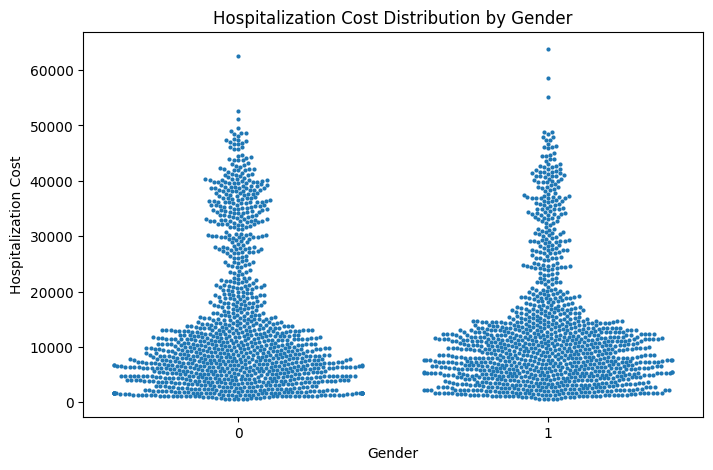

In [84]:
plt.figure(figsize=(8, 5))
sns.swarmplot(x="Gender", y="charges", data=ht, size=3)
plt.title("Hospitalization Cost Distribution by Gender")
plt.xlabel("Gender")
plt.ylabel("Hospitalization Cost")
plt.show()

10. State how the distribution is different across gender and tiers of hospitals

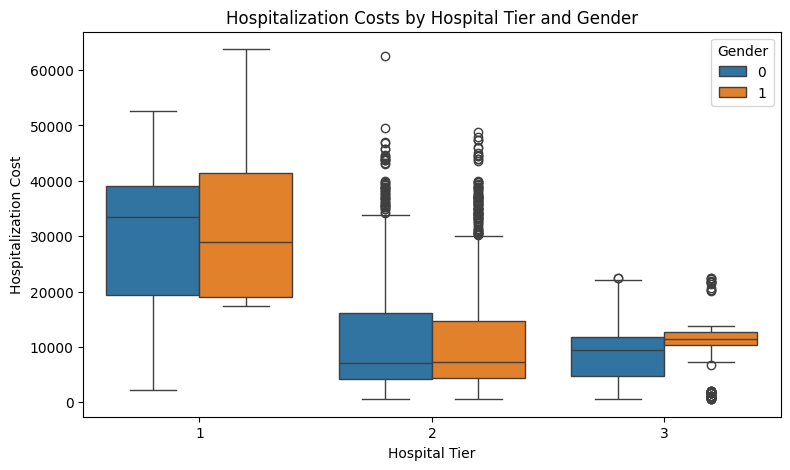

In [85]:
plt.figure(figsize=(9, 5))
sns.boxplot(x="Hospital tier", y="charges", hue="Gender", data=ht)
plt.title("Hospitalization Costs by Hospital Tier and Gender")
plt.xlabel("Hospital Tier")
plt.ylabel("Hospitalization Cost")
plt.show()

In [86]:
gender_tier_summary = ht.groupby(["Gender", "Hospital tier"])["charges"].agg(["count", "mean", "median", "min", "max"])
gender_tier_summary

count          mean     median       min       max
Gender Hospital tier                                                    
0      1                207  30004.264638  33475.820   2302.30  52590.83
       2                556  12365.093813   7136.520    563.84  62592.87
       3                397   8636.529118   9391.350    604.54  22462.04
1      1                 93  30416.300968  28923.140  17479.53  63770.43
       2                778  11526.268522   7262.660    600.00  48824.45
       3                294  10636.497245  11428.115    646.14  22478.60

11. Create a radar chart to showcase the median hospitalization cost for each tier of hospitals

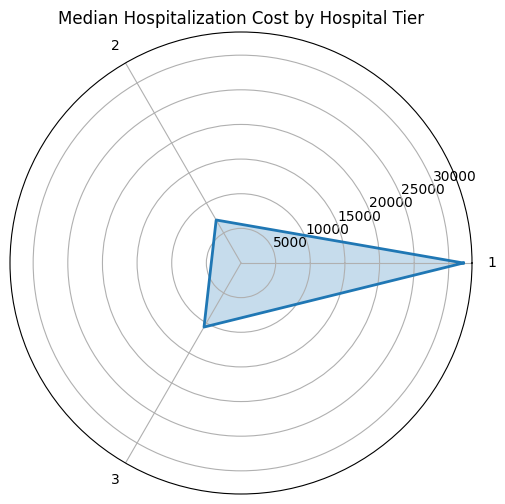

,charges
Hospital tier,
1,32097.435
2,7168.760
3,10676.830


In [87]:
median_cost = ht.groupby("Hospital tier")["charges"].median().sort_index()

labels = median_cost.index.tolist()
values = median_cost.values.tolist()

values += values[:1]

angles = np.linspace(0, 2 * np.pi, len(labels), endpoint=False).tolist()
angles += angles[:1]

plt.figure(figsize=(6, 6))
ax = plt.subplot(111, polar=True)

ax.plot(angles, values, linewidth=2)
ax.fill(angles, values, alpha=0.25)

ax.set_xticks(angles[:-1])
ax.set_xticklabels(labels)

plt.title("Median Hospitalization Cost by Hospital Tier")
plt.show()

median_cost

12. Create a frequency table and a stacked bar chart to visualize the count of people in the different
tiers of cities and hospitals

In [88]:
freq_table = pd.crosstab(ht["City tier"], ht["Hospital tier"])
freq_table

Hospital tier,1,2,3
City tier,,,
1,85,403,241
2,106,479,222
3,109,452,228


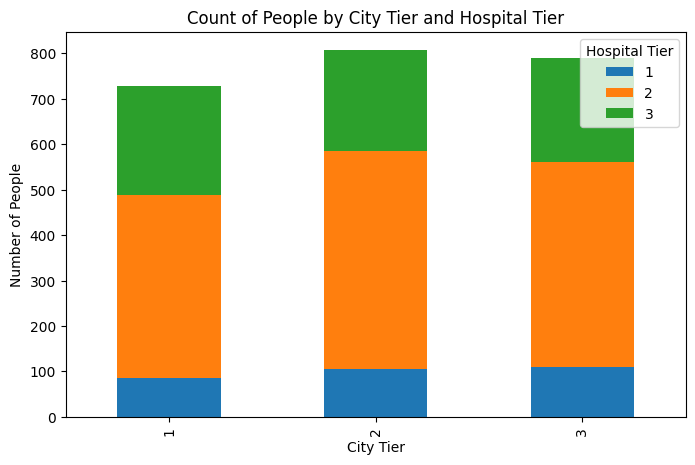

In [89]:
freq_table.plot(kind="bar", stacked=True, figsize=(8, 5))

plt.title("Count of People by City Tier and Hospital Tier")
plt.xlabel("City Tier")
plt.ylabel("Number of People")
plt.legend(title="Hospital Tier")
plt.show()

13. Test the following null hypotheses:

a. The average hospitalization costs for the three types of hospitals are not significantly different.

In [90]:
from scipy.stats import f_oneway

hospital_groups = [
    group["charges"].dropna()
    for name, group in ht.groupby("Hospital tier")
]

f_stat, p_value = f_oneway(*hospital_groups)

print("F-statistic:", f_stat)
print("P-value:", p_value)

if p_value < 0.05:
    print("Reject H0: Hospital tier has a significant effect on hospitalization cost.")
else:
    print("Fail to reject H0: Hospital tier costs are not significantly different.")

F-statistic: 493.98956631117625
P-value: 1.7738221310852664e-179
Reject H0: Hospital tier has a significant effect on hospitalization cost.


b. The average hospitalization costs for the three types of cities are not significantly different.

In [91]:
city_groups = [
    group["charges"].dropna()
    for name, group in ht.groupby("City tier")
]

f_stat, p_value = f_oneway(*city_groups)

print("F-statistic:", f_stat)
print("P-value:", p_value)

if p_value < 0.05:
    print("Reject H0: City tier has a significant effect on hospitalization cost.")
else:
    print("Fail to reject H0: City tier costs are not significantly different.")

F-statistic: 1.4543557561814688
P-value: 0.23376344386881315
Fail to reject H0: City tier costs are not significantly different.


C. The average hospitalization cost for smokers is not significantly different from the average cost
for nonsmokers.

In [92]:
from scipy.stats import ttest_ind
smoker_cost = ht[ht["smoker"] == 1]["charges"].dropna()
nonsmoker_cost = ht[ht["smoker"] == 0]["charges"].dropna()

t_stat, p_value = ttest_ind(smoker_cost, nonsmoker_cost, equal_var=False)

print("T-statistic:", t_stat)
print("P-value:", p_value)

if p_value < 0.05:
    print("Reject H0: Smokers and non-smokers have significantly different hospitalization costs.")
else:
    print("Fail to reject H0: No significant cost difference between smokers and non-smokers.")

T-statistic: 56.316832285932286
P-value: 6.697431845033993e-238
Reject H0: Smokers and non-smokers have significantly different hospitalization costs.


d. Smoking and heart issues are independent.

In [93]:
contingency_table = pd.crosstab(ht["smoker"], ht["Heart Issues"])
contingency_table

Heart Issues,0,1
smoker,,
0,1108,731
1,297,189


In [94]:
from scipy.stats import chi2_contingency

chi2, p_value, dof, expected = chi2_contingency(contingency_table)

print("Chi-square:", chi2)
print("P-value:", p_value)
print("Degrees of freedom:", dof)

if p_value < 0.05:
    print("Reject H0: Smoking and heart issues are dependent.")
else:
    print("Fail to reject H0: Smoking and heart issues are independent.")

Chi-square: 0.08588150449910657
P-value: 0.7694797581780767
Degrees of freedom: 1
Fail to reject H0: Smoking and heart issues are independent.


Machine learning

1. Examine the correlation between predictors to identify highly correlated predictors

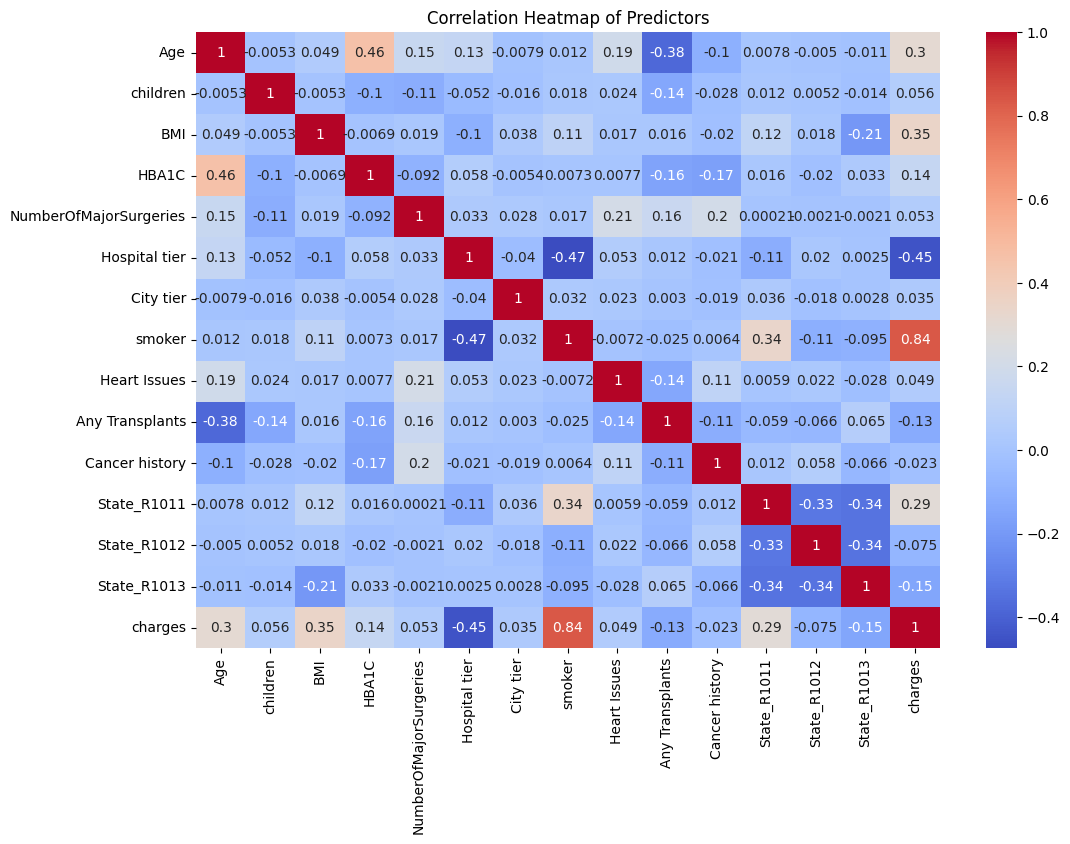

In [95]:
corr_cols = [
    "Age", "children", "BMI", "HBA1C", "NumberOfMajorSurgeries",
    "Hospital tier", "City tier",
    "smoker", "Heart Issues", "Any Transplants",
    "Cancer history",
    "State_R1011", "State_R1012", "State_R1013",
    "charges"
]

plt.figure(figsize=(12, 8))
sns.heatmap(ht[corr_cols].corr(), annot=True, cmap="coolwarm")
plt.title("Correlation Heatmap of Predictors")
plt.show()

2. Develop a regression model Linear or Ridge. Evaluate the model with k-fold cross validation.

In [96]:
from sklearn.model_selection import StratifiedKFold, GridSearchCV
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.linear_model import Ridge
from sklearn.ensemble import GradientBoostingRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

In [98]:
model_features = [
    "Age", "children", "BMI", "HBA1C", "NumberOfMajorSurgeries",
    "Hospital tier", "City tier",
    "smoker", "Heart Issues", "Any Transplants",
    "Cancer history",
    "State_R1011", "State_R1012", "State_R1013",
    "Gender"
]

model_df = ht.dropna(subset=model_features + ["charges"]).copy().reset_index(drop=True)

X = model_df[model_features]
y = model_df["charges"]

print("Model dataset shape:", model_df.shape)

Model dataset shape: (2325, 24)


In [99]:
# Create stratification bins for regression target
model_df["cost_bin"] = pd.qcut(
    model_df["charges"],
    q=5,
    labels=False,
    duplicates="drop"
)

# Create fold variable
model_df["fold"] = -1

skf = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

for fold, (train_idx, valid_idx) in enumerate(skf.split(model_df, model_df["cost_bin"])):
    model_df.loc[valid_idx, "fold"] = fold + 1

model_df["fold"].value_counts().sort_index()

,count
fold,
1,465
2,465
3,465
4,465
5,465


In [102]:
numeric_features = [
    "Age", "children", "BMI", "HBA1C", "NumberOfMajorSurgeries",
    "Hospital tier", "City tier",
    "smoker", "Heart Issues", "Any Transplants",
    "Cancer history",
    "State_R1011", "State_R1012", "State_R1013"
]

categorical_features = ["Gender"]

preprocessor = ColumnTransformer([
    ("num", StandardScaler(), numeric_features),
    ("cat", OneHotEncoder(handle_unknown="ignore"), categorical_features)
])

# Create custom CV splits using fold variable
X = model_df[model_features]
y = model_df["charges"]

cv_splits = []

for fold in sorted(model_df["fold"].unique()):
    train_idx = model_df.index[model_df["fold"] != fold].to_numpy()
    valid_idx = model_df.index[model_df["fold"] == fold].to_numpy()
    cv_splits.append((train_idx, valid_idx))

In [103]:
ridge_pipe = Pipeline([
    ("preprocessor", preprocessor),
    ("model", Ridge())
])

ridge_params = {
    "model__alpha": [0.01, 0.1, 1, 10, 100]
}

ridge_search = GridSearchCV(
    ridge_pipe,
    ridge_params,
    cv=cv_splits,
    scoring="neg_mean_absolute_error"
)

ridge_search.fit(X, y)

print("Best Ridge Parameters:", ridge_search.best_params_)
print("Best Ridge MAE:", -ridge_search.best_score_)

Best Ridge Parameters: {'model__alpha': 0.01}
Best Ridge MAE: 2741.301818762014


Gradient boosting regression with hyperparameter tuning.

In [104]:
gb_pipe = Pipeline([
    ("preprocessor", preprocessor),
    ("model", GradientBoostingRegressor(random_state=42))
])

gb_params = {
    "model__n_estimators": [100, 200],
    "model__learning_rate": [0.05, 0.1],
    "model__max_depth": [2, 3]
}

gb_search = GridSearchCV(
    gb_pipe,
    gb_params,
    cv=cv_splits,
    scoring="neg_mean_absolute_error"
)

gb_search.fit(X, y)

print("Best Gradient Boosting Parameters:", gb_search.best_params_)
print("Best Gradient Boosting MAE:", -gb_search.best_score_)

Best Gradient Boosting Parameters: {'model__learning_rate': 0.05, 'model__max_depth': 3, 'model__n_estimators': 200}
Best Gradient Boosting MAE: 2078.378162407532


In [105]:
results = pd.DataFrame({
    "Model": ["Ridge Regression", "Gradient Boosting"],
    "Best MAE": [-ridge_search.best_score_, -gb_search.best_score_]
})

results

,Model,Best MAE
0,Ridge Regression,2741.301819
1,Gradient Boosting,2078.378162


In [106]:
if gb_search.best_score_ > ridge_search.best_score_:
    best_model = gb_search.best_estimator_
    best_model_name = "Gradient Boosting"
else:
    best_model = ridge_search.best_estimator_
    best_model_name = "Ridge Regression"

print("Best model:", best_model_name)

Best model: Gradient Boosting


Gradient boost variable importance and redundent variables

In [107]:
best_gb = gb_search.best_estimator_

feature_names = best_gb.named_steps["preprocessor"].get_feature_names_out()
importances = best_gb.named_steps["model"].feature_importances_

importance_df = pd.DataFrame({
    "Feature": feature_names,
    "Importance": importances
}).sort_values(by="Importance", ascending=False)

importance_df

,Feature,Importance
7,num__smoker,0.751476
2,num__BMI,0.112226
0,num__Age,0.092810
5,num__Hospital tier,0.021345
11,num__State_R1011,0.007265
1,num__children,0.005885
13,num__State_R1013,0.004541
3,num__HBA1C,0.003226
4,num__NumberOfMajorSurgeries,0.000349
14,cat__Gender_0,0.000304


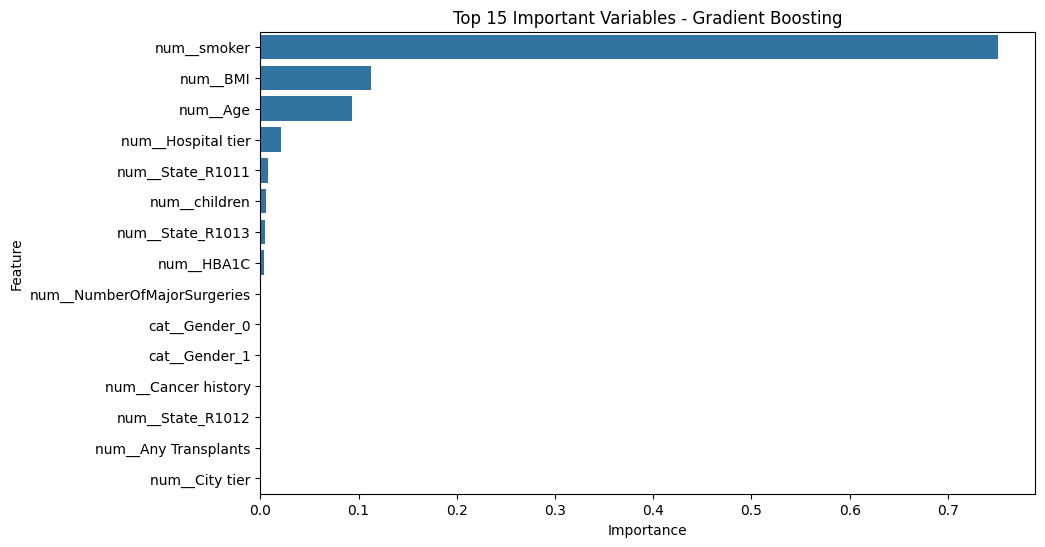

In [108]:
plt.figure(figsize=(10, 6))
sns.barplot(x="Importance", y="Feature", data=importance_df.head(15))
plt.title("Top 15 Important Variables - Gradient Boosting")
plt.xlabel("Importance")
plt.ylabel("Feature")
plt.show()

In [111]:
redundant_variables = importance_df[importance_df["Importance"] < 0.01]
redundant_variables

,Feature,Importance
11,num__State_R1011,0.007265
1,num__children,0.005885
13,num__State_R1013,0.004541
3,num__HBA1C,0.003226
4,num__NumberOfMajorSurgeries,0.000349
14,cat__Gender_0,0.000304
15,cat__Gender_1,0.000275
10,num__Cancer history,0.000130
12,num__State_R1012,0.000049
9,num__Any Transplants,0.000045


3. Case scenario:
Estimate the cost of hospitalization for Christopher, Ms. Jayna (Date of
birth 12/28/1988; height 170 cm; and weight 85 kgs). She lives with her partner and two children
in a tier-1 city, and her state’s State ID is R1011. She was found to be nondiabetic (HbA1c = 5.8).
She smokes but is otherwise healthy. She has had no transplants or major surgeries. Her father
died of lung cancer. Hospitalization costs will be estimated using tier-1 hospitals.

In [120]:
case_age = int(np.floor((analysis_date - pd.Timestamp("1988-12-28")).days / 365.25))
case_bmi = 85 / (1.70 ** 2)

case = pd.DataFrame([{
    "Age": case_age,
    "children": 2,
    "BMI": case_bmi,
    "HBA1C": 5.8,
    "NumberOfMajorSurgeries": 0,
    "Hospital tier": 1,
    "City tier": 1,
    "smoker": 1,
    "Heart Issues": 0,
    "Any Transplants": 0,
    "Cancer history": 1,
    "State_R1011": 1,
    "State_R1012": 0,
    "State_R1013": 0,
    "Gender": 1
}])


4. Find the predicted hospitalization cost using the best models

In [121]:
predicted_cost = best_model.predict(case)

print("Best model used:", best_model_name)
print("Ms. Jayna Christopher age:", case_age)
print("Ms. Jayna Christopher BMI:", round(case_bmi, 2))
print("Predicted hospitalization cost:", round(predicted_cost[0], 2))

Best model used: Gradient Boosting
Ms. Jayna Christopher age: 37
Ms. Jayna Christopher BMI: 29.41
Predicted hospitalization cost: 27929.39


In [122]:
ht.to_csv("cleaned_healthcare_data_for_tableau.csv", index=False)